# Student Performance Prediction Using Machine Learning

## Project Overview

This project aims to analyze student performance data and build machine learning
models to predict students' mathematics scores.

Two machine learning models will be trained and evaluated:

1. Linear Regression
2. Random Forest Regression

The models will be compared using appropriate regression metrics.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Loading the Dataset

The dataset contains information about students such as gender,
race/ethnicity, parental education, lunch type, test preparation course,
and their mathematics, reading, and writing scores.


In [3]:
df = pd.read_csv("exams.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 2. Understanding the Dataset

First, we inspect the number of rows, columns, data types,
and general structure of the dataset.

In [4]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 8)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [5]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## 3. Checking Missing Values

Missing values can negatively affect machine learning models.
Therefore, we check every column for missing data.

In [6]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [7]:
df.isnull().sum().sum()

np.int64(0)

In [8]:
df = df.dropna()

## 4. Checking Duplicate Records

Duplicate records may affect the results of machine learning models.
Therefore, duplicate rows are identified and removed.

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1000, 8)


In [11]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course'],
      dtype='object')


In [12]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
Index(['math score', 'reading score', 'writing score'], dtype='object')


In [13]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numerical_columns)

Numerical Columns:
Index(['math score', 'reading score', 'writing score'], dtype='object')


## 5. Exploratory Data Analysis

### Distribution of Mathematics Scores

The following graph shows the distribution of students'
mathematics scores.


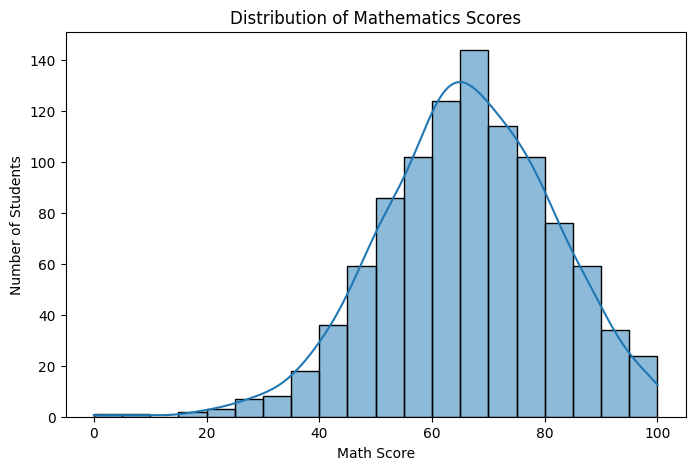

In [14]:
plt.figure(figsize=(8,5))

sns.histplot(df["math score"], bins=20, kde=True)

plt.title("Distribution of Mathematics Scores")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")

plt.show()

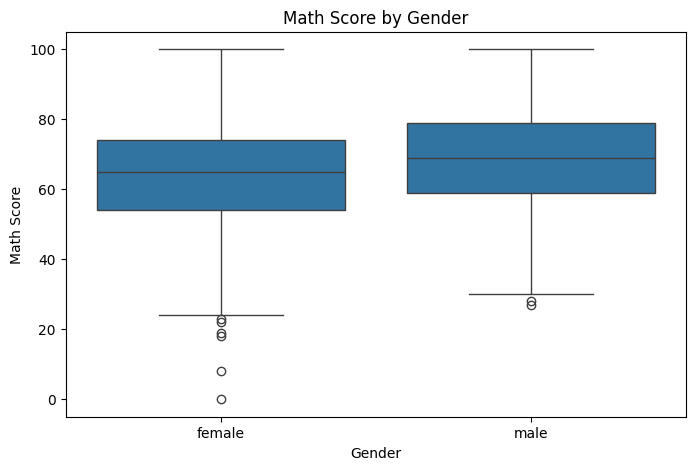

In [15]:
plt.figure(figsize=(8,5))

sns.boxplot(x="gender", y="math score", data=df)

plt.title("Math Score by Gender")
plt.xlabel("Gender")
plt.ylabel("Math Score")

plt.show()

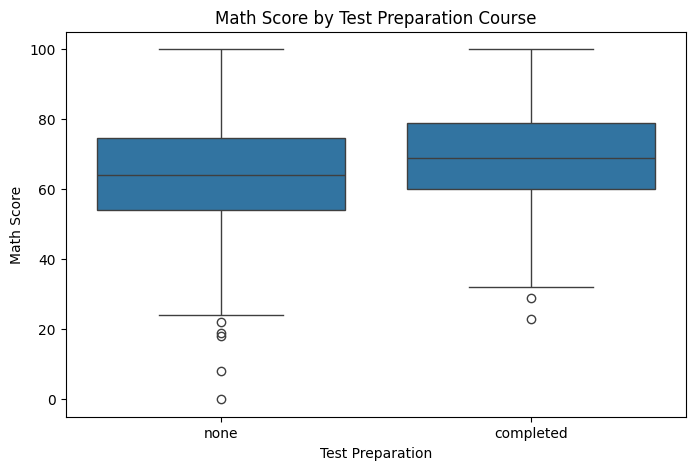

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x="test preparation course",
    y="math score",
    data=df
)

plt.title("Math Score by Test Preparation Course")
plt.xlabel("Test Preparation")
plt.ylabel("Math Score")

plt.show()

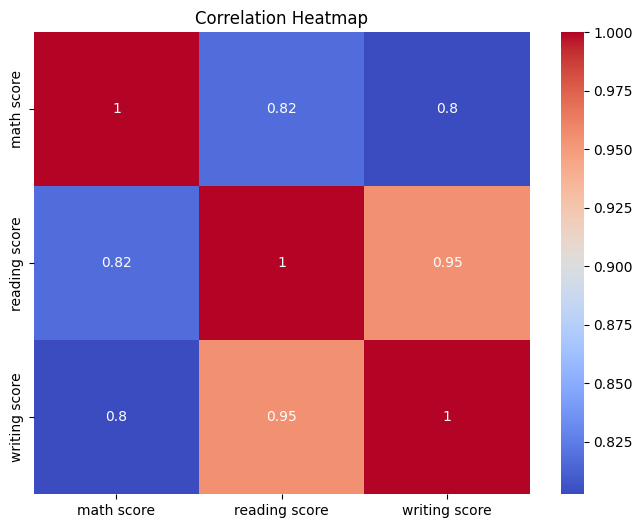

In [17]:
plt.figure(figsize=(8,6))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")

plt.show()

## 6. Feature and Target Selection

The target variable is `math score`.

The remaining columns are used as input features.


In [18]:
X = df.drop("math score", axis=1)

y = df["math score"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  reading score  writing score  
0                    none             72             74  
1               completed             90             88  
2                    none             95             93  
3                    none             57             44  
4                    none             78             75  

Target:
0    72
1    69
2    90
3    47
4    76
Name: math score, dtype: int64


In [19]:
categorical_features = X.select_dtypes(include=["object"]).columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

print("Categorical Features:")
print(list(categorical_features))

print("\nNumerical Features:")
print(list(numerical_features))

Categorical Features:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']

Numerical Features:
['reading score', 'writing score']


In [20]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

## 7. Splitting the Dataset

The dataset is divided into training and testing sets.

80% of the data is used for training and 20% is used for testing.


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 7)
Testing data: (200, 7)


## 8. Model 1 — Linear Regression

Linear Regression is a supervised machine learning algorithm used
for predicting continuous numerical values.

It attempts to model the relationship between input features and
the target variable using a linear equation.

In [22]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

In [23]:
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression Predictions:")
print(y_pred_linear[:10])

Linear Regression Predictions:
[76.3879697  58.88597004 76.99026483 76.85180448 87.62737816 79.0140238
 64.65460865 53.00791885 74.18471015 49.21353815]


In [24]:
mae_linear = mean_absolute_error(y_test, y_pred_linear)

rmse_linear = np.sqrt(
    mean_squared_error(y_test, y_pred_linear)
)

r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae_linear)
print("RMSE:", rmse_linear)
print("R² Score:", r2_linear)

Linear Regression Results
-------------------------
MAE : 4.214763142474852
RMSE: 5.393993869732845
R² Score: 0.8804332983749564


## 9. Model 2 — Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm
that combines multiple decision trees.

It can capture nonlinear relationships between features and the
target variable and is often effective for tabular datasets.

In [25]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

random_forest_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different t

In [26]:
y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest Predictions:")
print(y_pred_rf[:10])

Random Forest Predictions:
[77.58 55.8  76.74 77.21 80.2  85.29 65.48 54.57 74.2  52.  ]


In [27]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(
    mean_squared_error(y_test, y_pred_rf)
)

r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Results")
print("--------------------------------")
print("MAE :", mae_rf)
print("RMSE:", rmse_rf)
print("R² Score:", r2_rf)

Random Forest Regression Results
--------------------------------
MAE : 4.665547023809524
RMSE: 6.0258939578996005
R² Score: 0.8507781838302096


## 10. Model Comparison

The performance of Linear Regression and Random Forest Regression
is compared using MAE, RMSE, and R² Score.

For MAE and RMSE, lower values indicate better performance.

For R² Score, a higher value indicates better performance.

In [28]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mae_linear,
        mae_rf
    ],
    "RMSE": [
        rmse_linear,
        rmse_rf
    ],
    "R2 Score": [
        r2_linear,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.214763,5.393994,0.880433
1,Random Forest Regression,4.665547,6.025894,0.850778


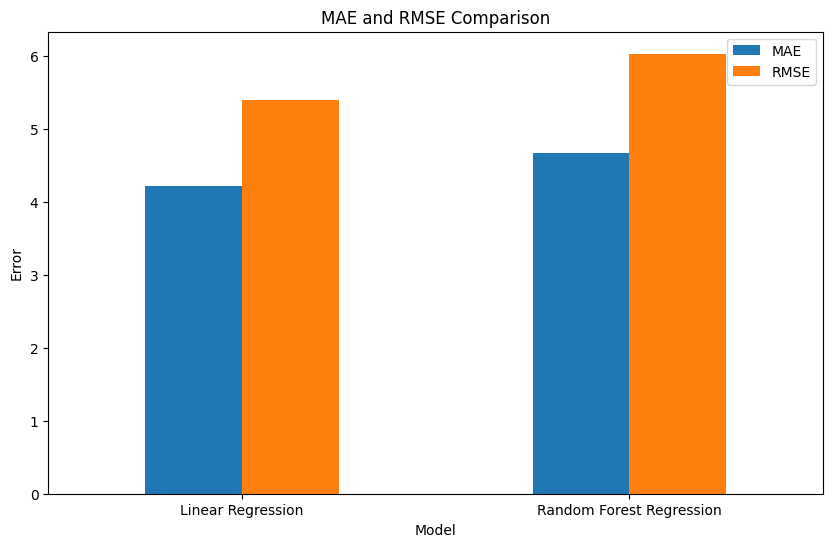

In [29]:
results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("MAE and RMSE Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)

plt.show()

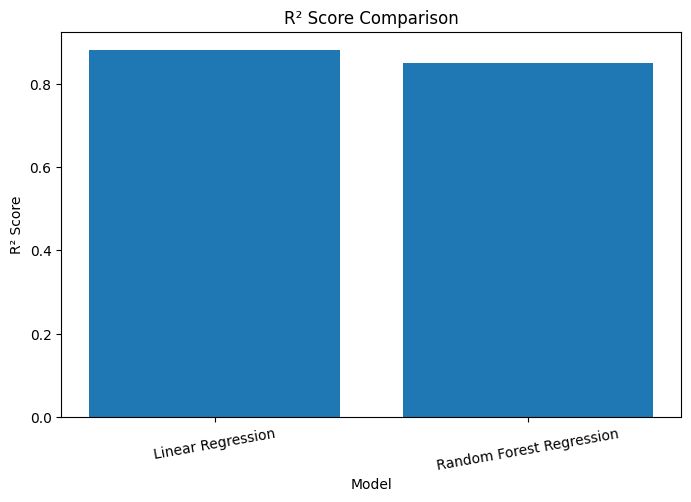

In [30]:
plt.figure(figsize=(8,5))

plt.bar(
    results["Model"],
    results["R2 Score"]
)

plt.title("R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=10)

plt.show()

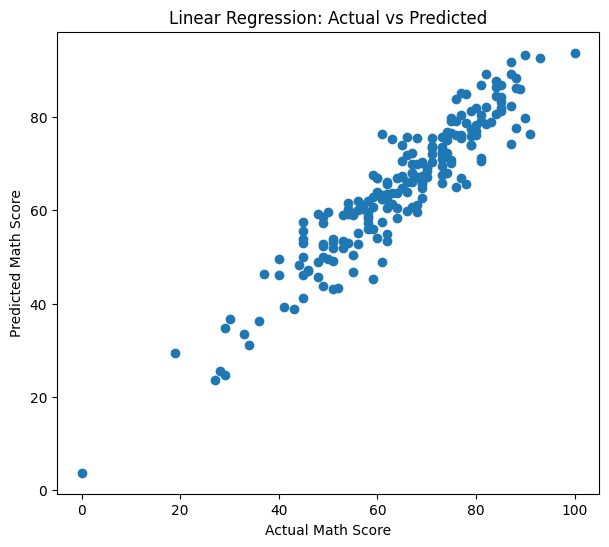

In [31]:
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    y_pred_linear
)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")

plt.title("Linear Regression: Actual vs Predicted")

plt.show()

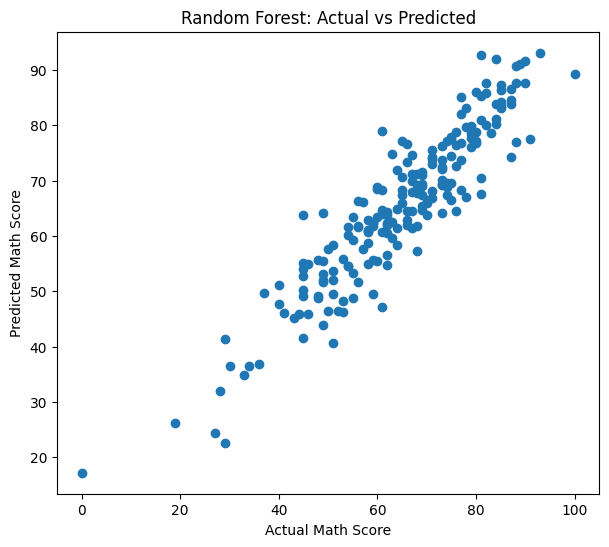

In [32]:
plt.figure(figsize=(7,6))

plt.scatter(
    y_test,
    y_pred_rf
)

plt.xlabel("Actual Math Score")
plt.ylabel("Predicted Math Score")

plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [33]:
if r2_rf > r2_linear:
    better_model = "Random Forest Regression"
else:
    better_model = "Linear Regression"

print("Model with higher R² score:", better_model)

Model with higher R² score: Linear Regression


## 11. Why Does One Model Perform Better?

The better-performing model is determined using the evaluation metrics.

A model is considered to have better predictive performance when it
has:

- Lower Mean Absolute Error (MAE)
- Lower Root Mean Squared Error (RMSE)
- Higher R² Score

If Random Forest achieves a higher R² score and lower errors than
Linear Regression, it indicates that Random Forest captures more
complex and nonlinear relationships in the student performance data.

If Linear Regression performs better, the results indicate that the
relationships in this dataset can be represented effectively using
a simpler linear model.

The conclusion should therefore be based on the actual evaluation
results obtained from the dataset.

In [34]:
print("FINAL MODEL RESULTS")
print("===================")

display(results)

FINAL MODEL RESULTS


,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.214763,5.393994,0.880433
1,Random Forest Regression,4.665547,6.025894,0.850778


# 12. Conclusion

In this project, student performance data was analyzed and prepared
for machine learning.

The dataset was cleaned by checking missing values and duplicate
records. Categorical variables were converted into numerical
features using One-Hot Encoding.

Two machine learning regression models were trained:

1. Linear Regression
2. Random Forest Regression

The models were evaluated using Mean Absolute Error (MAE),
Root Mean Squared Error (RMSE), and R² Score.

The model with lower MAE and RMSE and higher R² Score provides
better predictive performance on the test dataset.

The comparison demonstrates how different machine learning
algorithms can produce different results on the same dataset.
The final model selection is based on the evaluation metrics
obtained from the test data.

In [35]:
results.to_csv(
    "student_performance_model_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


In [36]:
import joblib

joblib.dump(
    random_forest_model,
    "student_performance_random_forest.pkl"
)

print("Model saved successfully!")

Model saved successfully!


# 13. Feature Engineering

Feature engineering is the process of creating new meaningful
features from existing variables.

For student performance, we create:

- Average Score
- Total Score
- Score Range

These features may provide additional information about overall
student performance.

In [37]:
df["average_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

df["total_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
)

df["score_range"] = (
    df[["math score", "reading score", "writing score"]].max(axis=1)
    -
    df[["math score", "reading score", "writing score"]].min(axis=1)
)

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score,total_score,score_range
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667,218,2
1,female,group C,some college,standard,completed,69,90,88,82.333333,247,21
2,female,group B,master's degree,standard,none,90,95,93,92.666667,278,5
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333,148,13
4,male,group C,some college,standard,none,76,78,75,76.333333,229,3


In [38]:
df["reading_writing_average"] = (
    df["reading score"] +
    df["writing score"]
) / 2

df["reading_writing_difference"] = (
    df["reading score"] -
    df["writing score"]
).abs()

In [39]:
X_improved = df.drop(
    [
        "math score",
        "average_score",
        "total_score"
    ],
    axis=1
)

y_improved = df["math score"]

X_improved.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,reading score,writing score,score_range,reading_writing_average,reading_writing_difference
0,female,group B,bachelor's degree,standard,none,72,74,2,73.0,2
1,female,group C,some college,standard,completed,90,88,21,89.0,2
2,female,group B,master's degree,standard,none,95,93,5,94.0,2
3,male,group A,associate's degree,free/reduced,none,57,44,13,50.5,13
4,male,group C,some college,standard,none,78,75,3,76.5,3


In [40]:
X_train_imp, X_test_imp, y_train_imp, y_test_imp = train_test_split(
    X_improved,
    y_improved,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_imp.shape)
print("Testing data:", X_test_imp.shape)

Training data: (800, 10)
Testing data: (200, 10)


In [41]:
categorical_features_imp = X_improved.select_dtypes(
    include=["object"]
).columns

numerical_features_imp = X_improved.select_dtypes(
    include=["int64", "float64"]
).columns

preprocessor_imp = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features_imp
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_imp
        )
    ]
)

## 14. Cross-Validation

Cross-validation provides a more reliable estimate of model
performance.

In 5-fold cross-validation, the dataset is divided into five parts.
The model is trained on four parts and validated on the remaining
part. This process is repeated five times.

In [42]:
from sklearn.model_selection import cross_val_score

rf_cv_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_imp),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                random_state=42
            )
        )
    ]
)

cv_scores = cross_val_score(
    rf_cv_model,
    X_improved,
    y_improved,
    cv=5,
    scoring="r2"
)

print("Cross-validation R² scores:")
print(cv_scores)

print("\nMean Cross-validation R²:",
      cv_scores.mean())

Cross-validation R² scores:
[0.92922189 0.94309689 0.91203688 0.94921968 0.92541126]

Mean Cross-validation R²: 0.9317973207710721


## 15. Hyperparameter Tuning

Hyperparameters control how a machine learning algorithm learns.

GridSearchCV tests different combinations of hyperparameters and
selects the combination that provides the best cross-validation
performance.

In [43]:
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_imp),
        (
            "model",
            RandomForestRegressor(
                random_state=42
            )
        )
    ]
)

In [44]:
param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

In [45]:
grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(
    X_train_imp,
    y_train_imp
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [None, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for eac

In [46]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation R²:")
print(grid_search.best_score_)

Best Parameters:
{'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best Cross-Validation R²:
0.9324530740828288


In [47]:
best_model = grid_search.best_estimator_

y_pred_improved = best_model.predict(
    X_test_imp
)

In [48]:
mae_improved = mean_absolute_error(
    y_test_imp,
    y_pred_improved
)

rmse_improved = np.sqrt(
    mean_squared_error(
        y_test_imp,
        y_pred_improved
    )
)

r2_improved = r2_score(
    y_test_imp,
    y_pred_improved
)

print("Improved Random Forest Results")
print("--------------------------------")
print("MAE :", mae_improved)
print("RMSE:", rmse_improved)
print("R² Score:", r2_improved)

Improved Random Forest Results
--------------------------------
MAE : 2.5587
RMSE: 3.8992405029697763
R² Score: 0.9375187948141354


In [49]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    
    "MAE": [
        mae_linear,
        mae_rf,
        mae_improved
    ],
    
    "RMSE": [
        rmse_linear,
        rmse_rf,
        rmse_improved
    ],
    
    "R2 Score": [
        r2_linear,
        r2_rf,
        r2_improved
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,4.214763,5.393994,0.880433
1,Original Random Forest,4.665547,6.025894,0.850778
2,Tuned Random Forest,2.558700,3.899241,0.937519


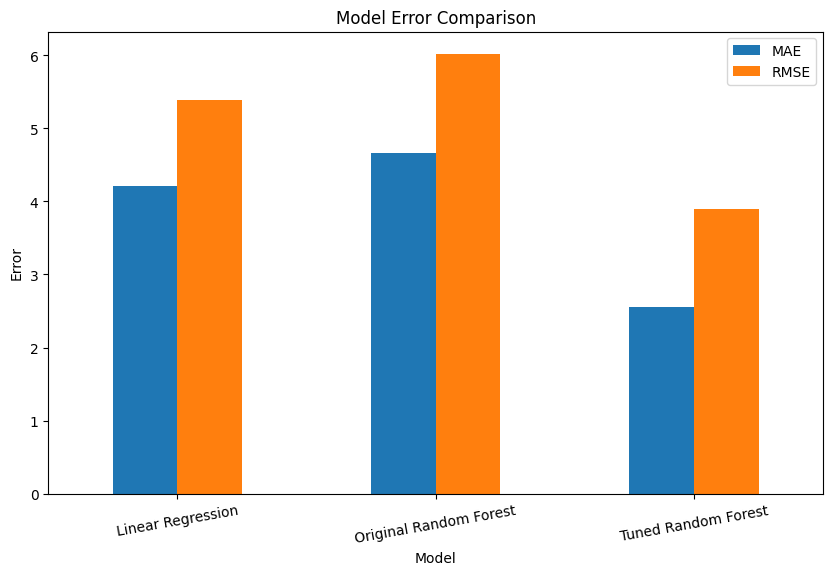

In [50]:
comparison.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Model Error Comparison")
plt.ylabel("Error")
plt.xticks(rotation=10)

plt.show()

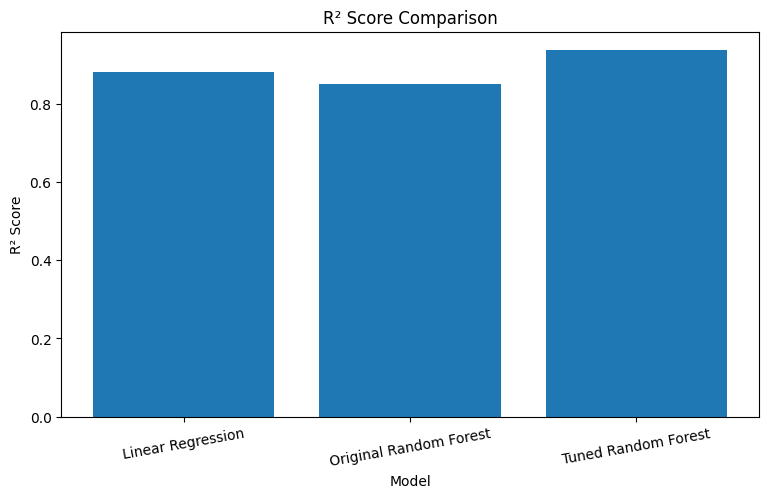

In [51]:
plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Model"],
    comparison["R2 Score"]
)

plt.title("R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=10)

plt.show()

In [52]:
r2_improvement = (
    (r2_improved - r2_rf)
    / abs(r2_rf)
) * 100

mae_improvement = (
    (mae_rf - mae_improved)
    / mae_rf
) * 100

rmse_improvement = (
    (rmse_rf - rmse_improved)
    / rmse_rf
) * 100

print(f"R² improvement: {r2_improvement:.2f}%")
print(f"MAE improvement: {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

R² improvement: 10.20%
MAE improvement: 45.16%
RMSE improvement: 35.29%


In [53]:
if r2_improved > r2_rf:
    print("The tuned Random Forest improved the R² score.")
elif r2_improved < r2_rf:
    print("The tuned Random Forest did not improve the R² score.")
else:
    print("The R² score remained unchanged.")

The tuned Random Forest improved the R² score.


# 16. Findings and Discussion

Feature engineering was applied to create additional meaningful
features from the student performance data. Features that could
cause target leakage were excluded from the final model.

Five-fold cross-validation was used to obtain a more reliable
estimate of model performance.

Hyperparameter tuning was then performed on the Random Forest
Regression model using GridSearchCV.

The original Random Forest model was compared with the tuned
Random Forest model using MAE, RMSE, and R² Score.

A lower MAE and RMSE indicate lower prediction error, while a
higher R² Score indicates that the model explains more variation
in the target variable.

The tuned model should be considered improved only if its
performance on the test data supports the improvement. If the
tuned model does not outperform the original model, the results
are still useful because they demonstrate that additional
complexity and hyperparameter tuning do not always improve
generalization performance.

The final conclusion is therefore based on the actual experimental
results rather than assuming that the tuned model will always be
better.

In [54]:
comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Final comparison saved successfully.")

Final comparison saved successfully.
